In [1]:
# Some common data manipulation imports
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import LSTM, Dense
from tensorflow import keras
from keras.optimizers import Adam
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.preprocessing.image import ImageDataGenerator
import time
from keras.callbacks import TensorBoard
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, plot_confusion_matrix
import csv
from keras.utils.vis_utils import plot_model
from keras.callbacks import History
from matplotlib import pyplot as plt
#normalizing the data
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from pandas import DataFrame
from sklearn.metrics import classification_report, confusion_matrix
import time
from keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.metrics import mean_squared_error
from math import sqrt

#some other imports
import os
pd.set_option('display.max_rows', 100000)

# For stable output on each run
np.random.seed(3)

# To plot easily visible pictures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

Using TensorFlow backend.


In [2]:
original = pd.read_csv('500_nodes.csv')
original = original[['date', 'name', 'target']]
#train, test = train_test_split(original, test_size=0.2)

In [3]:
for i in range(0,50):
    print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49


In [4]:
rmse_list = []
for i in range(450,500):
    temp = original[(original['name'] == i)]
    times = temp[['date', 'target']]
    times.set_axis(times['date'], inplace=True)
    #times.drop(['date'], axis=1, inplace=True)
    t_data = times['target'].values
    t_data = t_data.reshape((-1,1))

    split_percent = 0.80
    split = int(split_percent*len(t_data))

    t_train = t_data[:split]
    t_test = t_data[split:]

    date_train = times['date'][:split]
    date_test = times['date'][split:]

#     print(t_train)
#     print(t_test)

    scaler = MinMaxScaler()
    t_train = scaler.fit_transform(t_train)
    t_test = scaler.transform(t_test)

    look_back = 7
    #3 = 2.4842117019480376

    train_generator = TimeseriesGenerator(t_train, t_train, length=look_back, batch_size=64)     
    test_generator = TimeseriesGenerator(t_test, t_test, length=look_back, batch_size=1)

    model=Sequential()
    # # watch out for return_sequence
    model.add(LSTM(100,activation='relu',input_shape=(look_back, 1),return_sequences=True))
#     model.add(Dropout(0.2))
#     model.add(LSTM(100,activation='relu',return_sequences=True))
#     model.add(LSTM(128,activation='relu',return_sequences=True))
#     model.add(Dropout(0.2))
#     model.add(LSTM(512,activation='relu',return_sequences=True))
#     model.add(Dropout(0.2))
#     model.add(LSTM(128,activation='relu',return_sequences=True))
#     model.add(Dropout(0.2))
    model.add(LSTM(32,activation='relu'))
    model.add(Dense(1))
    opt= Adam(lr=.0001)
    model.compile(optimizer=opt,loss='mse')
#     model.summary()
    model.fit(train_generator, epochs=10, verbose=0)
    
    loss_per_epoch = model.history.history['loss']
#     plt.plot(range(len(loss_per_epoch)),loss_per_epoch)
    
    last_train_batch = t_train[-(look_back):]
    last_train_batch = last_train_batch.reshape((1, look_back, 1))
    model.predict(last_train_batch)   
    # array([[0.6046513]], dtype=float32)
    test_predictions = []
    n_features = 1

    first_eval_batch = t_train[-(look_back):]
    current_batch = first_eval_batch.reshape((1, look_back, n_features))

    for i in range(len(t_test)):

        # get the prediction value for the first batch
        current_pred = model.predict(current_batch)[0]

        # append the prediction into the array
        test_predictions.append(current_pred) 

        # use the prediction to update the batch and remove the first value
        current_batch = np.append(current_batch[:,1:,:],[[current_pred]],axis=1)
    
    true_predictions = scaler.inverse_transform(test_predictions)
    test = times.iloc[split:]    

    test['Predictions'] = true_predictions
#     test.plot(figsize=(14,5))
    

    rmse=sqrt(mean_squared_error(test['target'],test['Predictions']))
    print(rmse)
    rmse_list.append(rmse)

/Users/chandrikasaha/opt/anaconda3/envs/tf_keras/lib/python3.6/site-packages/ipykernel_launcher.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


2.5286696230944403


/Users/chandrikasaha/opt/anaconda3/envs/tf_keras/lib/python3.6/site-packages/ipykernel_launcher.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


0.0


/Users/chandrikasaha/opt/anaconda3/envs/tf_keras/lib/python3.6/site-packages/ipykernel_launcher.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


2.2469016724858966


KeyboardInterrupt: 

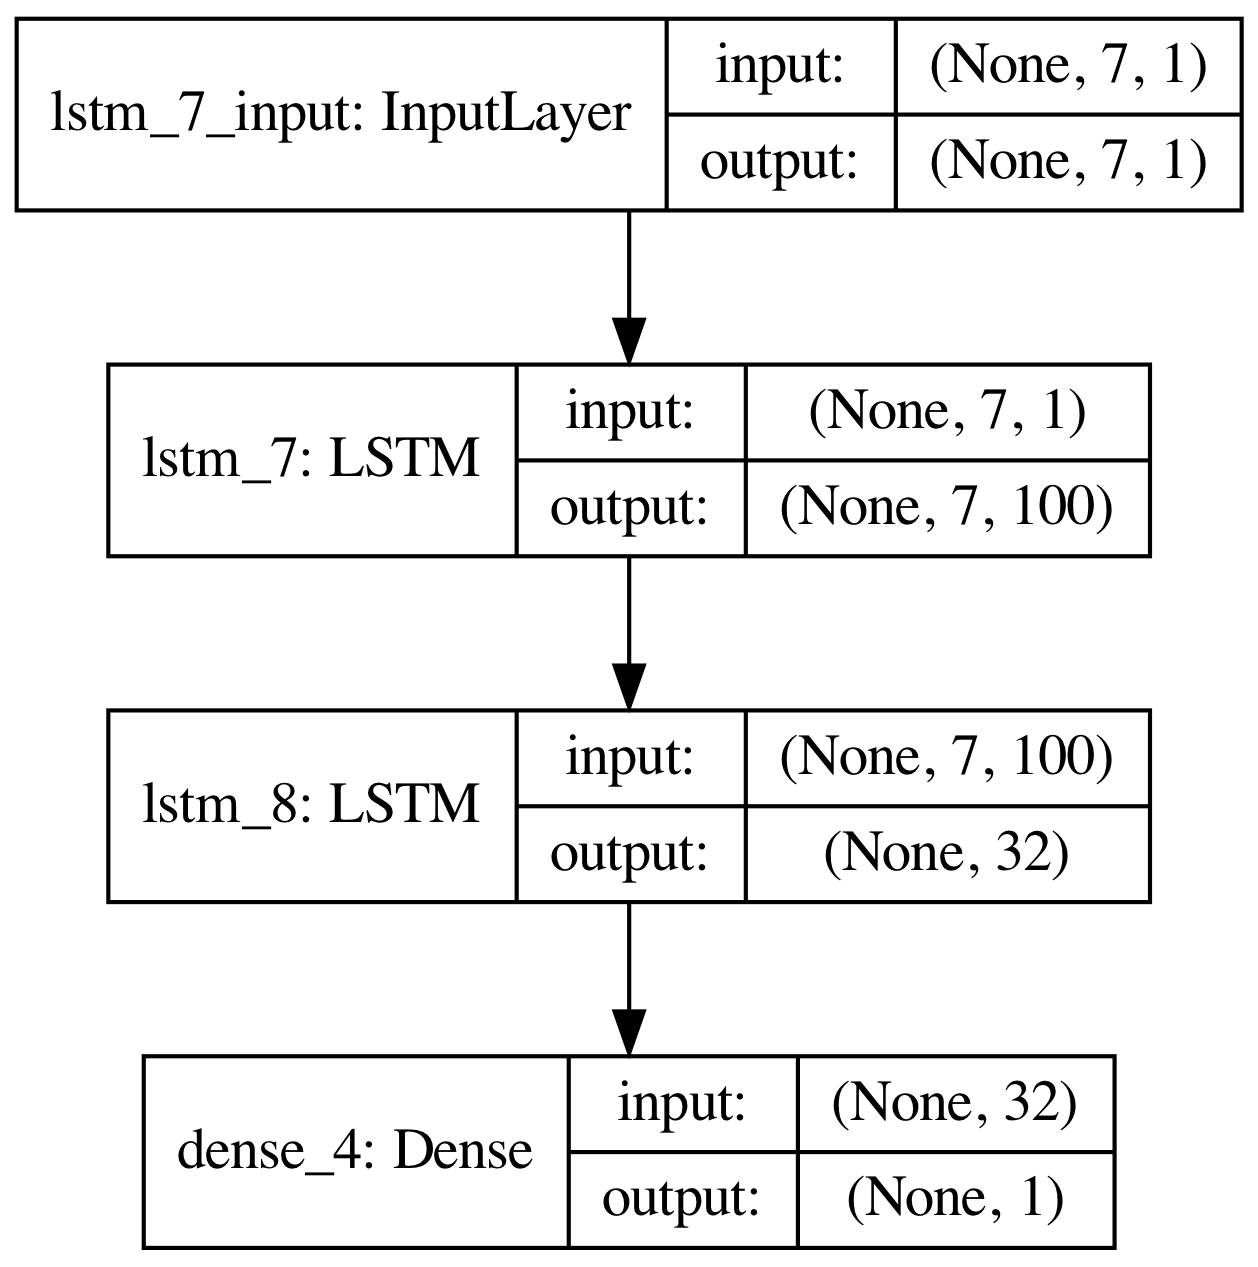

In [6]:
from keras.utils.vis_utils import plot_model

plot_model(model, 
           to_file='LSTM.png', rankdir='TB', show_shapes=True, show_layer_names=True, expand_nested=True, 
           dpi=300)

In [ ]:
rmse_list
m = sum(rmse_list) / len(rmse_list)
print(m)

In [ ]:
lst = [2.1632223708431284, 0.6165631871374938 , 0.4468410136850241, 0.48483410266562815 ] 
# m = sum(lst) / len(lst)
# print(m)

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
times.index = pd.to_datetime(times.index)
times.index.freq = pd.infer_freq(times.index)
results = seasonal_decompose(times['target'].iloc[0:50])
plt.figure(figsize = (10,7))
results.plot()

In [ ]:
t_test[0]

In [ ]:
test_predictions

In [ ]:
# from sklearn.metrics import r2_score
# i = 0
# prediction = model.predict_generator(test_generator)
# prediction = scaler.inverse_transform(prediction)
# t_test_t = scaler.inverse_transform(t_test)
# rmse = np.sqrt(np.mean((prediction - t_test_t[-(219 - look_back):]) ** 2))
# print(f'Node {i}: RMSE = {rmse}')
# mape = np.mean(np.abs((t_test_t[-(219 - look_back):] - prediction) / t_test_t[-(219 - look_back):])) * 100
# print(f'Node {i}: MAPE = {mape}')
# r2 = r2_score(t_test_t[-(219 - look_back):], prediction)
# print(f'Node {i}: R2 = {r2}')

In [ ]:
# prediction

In [ ]:
# for i in range(len(test_generator)):
#     x, y = test_generator[i]
#     print('Batch', i+1)
#     print('X:', x)
#     print('Y:', y)

In [ ]:
# t_test

In [ ]:
# plt.plot(t_train[0:100])

In [ ]:
test

In [ ]:
mse = [1,2,3]

In [ ]:
xs = [15, 18, 2, 36, 12, 78, 5, 6, 9]

import statistics
statistics.mean(xs)  # = 20.11111111111111